# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 11                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = False      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | sqlite3 3.45.1
Рабочая папка: pw2_work


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 11 — Общественный транспорт
Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON),
провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»

CSV  : Перевозчики        (справочник субъектов)
XLSX : Маршруты-рейсы          (события, объём в единицах: пассажиров)
JSON : Тарифы проезда          (цены, разрез: тип билета)

Объём генерации: субъектов 9, событий 5 500, уровень дефектов ★★★
Аналитическая задача: Выручка по типам билетов и пиковые месяцы


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       10   размер:      0.7 КБ
events.xlsx     строк:    5 536   размер:    194.8 КБ
prices.json     строк:   11 197   размер:   1383.5 КБ

Файлы лежат в: pw2_work/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [4]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Постройте профиль источника: по каждой колонке — тип, доля заполненности,
    число уникальных значений и два примера значений. Верните DataFrame."""
    rows = []
    for col in df.columns:
        s = df[col]
        nn = s.dropna()
        rows.append({
            "источник": name,
            "колонка": col,
            "строк": len(s),
            "тип значений": ", ".join(sorted({type(v).__name__ for v in nn})) or "—",
            "заполнено, %": round(100 * s.notna().mean(), 1),
            "уникальных": int(s.nunique(dropna=True)),
            "примеры": " | ".join(map(str, nn.drop_duplicates().head(2))),
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
# Заполните журнал проблем качества по шести измерениям. Для каждой найденной проблемы —
# строка с полями: измерение, источник, проблема, число строк, решение.
#   Полнота        — пропуски по колонкам
#   Уникальность   — полные дубликаты и повторы ключей (entity_id, event_id, price_id)
#   Согласованность— два формата даты, числа строками с валютой и пробелами
#   Валидность     — отрицательные цены, нулевой объём
#   Целостность    — записи с внешним ключом, которого нет в справочнике (в обе стороны)
#   Точность       — выбросы цен по правилу 3×IQR
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})
SRC_E, SRC_V, SRC_P = list(SOURCES)          # имена источников: CSV / XLSX / JSON

# --- вспомогательные «лёгкие» разборы только для аудита (полноценный разбор — на шаге 4) ----
price_num = pd.to_numeric(raw_prices["unit_price"].astype(str).str.replace(r"[^\d.\-]", "", regex=True),
                          errors="coerce")
vol_num = pd.to_numeric(raw_events["volume_units"].str.strip(), errors="coerce")
date_s = raw_events["event_date"].str.strip()
is_iso = date_s.str.match(r"^\d{4}-\d{2}-\d{2}$", na=False)
is_ru = date_s.str.match(r"^\d{2}\.\d{2}\.\d{4}$", na=False)

def iqr_outliers(s, k=3.0):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

# ----------------------------------------------------------------------------- Полнота
for src_name, df in SOURCES.items():
    for col in df.columns:
        n = int(df[col].isna().sum())
        if n:
            add_issue("Полнота", src_name, f"пропуски в «{col}» ({n / len(df):.1%} строк)", n,
                      "пропуск не заполняется нулём; непригодные для расчёта строки — в карантин")

# ----------------------------------------------------------------------------- Уникальность
add_issue("Уникальность", SRC_E, "полные дубликаты строк", raw_entities.duplicated().sum(),
          "удалить дубль, оставить первую запись; зафиксировать в журнале очистки")
add_issue("Уникальность", SRC_E, "повторы ключа entity_id", raw_entities.duplicated("entity_id").sum(),
          "оставить первую запись по ключу")
add_issue("Уникальность", SRC_V, "повторы ключа event_id (это полные дубликаты строк)",
          raw_events.duplicated("event_id").sum(), "оставить первую запись по event_id")
add_issue("Уникальность", SRC_P, "повторы ключа price_id (это полные дубликаты строк)",
          raw_prices.duplicated("price_id").sum(), "оставить первую запись по price_id")

# ----------------------------------------------------------------------------- Согласованность
add_issue("Согласованность", SRC_V, "дата в формате ДД.ММ.ГГГГ вместо ГГГГ-ММ-ДД", is_ru.sum(),
          "разобрать оба формата в единый datetime")
add_issue("Согласованность", SRC_V, "объём записан текстом с пробелом («180 »)",
          raw_events["volume_units"].dropna().str.contains(r"[^\d.]").sum(),
          "убрать пробелы, привести к числу")
add_issue("Согласованность", SRC_P, "цена записана строкой с валютой и пробелами («5 123.45 ₽»)",
          raw_prices["unit_price"].map(lambda v: isinstance(v, str)).sum(),
          "убрать валюту и разделители разрядов, привести к числу")
canon = raw_entities["entity_name"].str.strip().str.replace(r"\s+", " ", regex=True)
add_issue("Согласованность", SRC_E, "имя субъекта: лишние пробелы и/или ВЕРХНИЙ РЕГИСТР",
          ((raw_entities["entity_name"] != canon) | canon.str.isupper()).sum(),
          "привести к единому виду")
reg_mismatch = raw_entities.dropna(subset=["region"]).apply(
    lambda r: r["region"].casefold() not in r["entity_name"].casefold(), axis=1).sum()
add_issue("Согласованность", SRC_E, "регион не совпадает с городом в названии", reg_mismatch,
          "сверить с владельцем справочника")

# ----------------------------------------------------------------------------- Валидность
add_issue("Валидность", SRC_P, "отрицательная или нулевая цена", (price_num <= 0).sum(),
          "в карантин (quarantine_price), не удалять молча")
add_issue("Валидность", SRC_V, "нулевой или отрицательный объём", (vol_num <= 0).sum(), "в карантин")
add_issue("Валидность", SRC_V, "дата не распознана ни в одном формате",
          (date_s.notna() & ~is_iso & ~is_ru).sum(), "в карантин")

# ----------------------------------------------------------------------------- Целостность
ent_ids, ev_ids = set(raw_entities["entity_id"]), set(raw_events["event_id"])
add_issue("Целостность", SRC_V, "события с entity_id, которого нет в справочнике (сироты)",
          (~raw_events["entity_id"].isin(ent_ids)).sum(), "в карантин (quarantine_fk)")
add_issue("Целостность", SRC_E, "субъекты без единого события",
          len(ent_ids - set(raw_events["entity_id"])), "оставить в справочнике, пометить как неактивные")
add_issue("Целостность", SRC_P, "цены, ссылающиеся на несуществующее событие",
          (~raw_prices["event_id"].isin(ev_ids)).sum(), "в карантин")
add_issue("Целостность", SRC_V, "события без единой цены (выручку посчитать нельзя)",
          len(ev_ids - set(raw_prices["event_id"])), "исключить из расчёта выручки, учесть как ограничение")

# ----------------------------------------------------------------------------- Точность
pp = pd.DataFrame({"p": price_num, "cls": raw_prices["price_class"]})
pp = pp[pp["p"] > 0]
n_price_out = int(sum(iqr_outliers(g["p"]).sum() for _, g in pp.groupby("cls")))
add_issue("Точность", SRC_P, "выбросы цены по правилу 3×IQR внутри класса (сигнал, не ошибка)",
          n_price_out, "проверить с владельцем; в данных оставить, отметить флагом")
add_issue("Точность", SRC_V, "выбросы объёма по правилу 3×IQR (сигнал, не ошибка)",
          iqr_outliers(vol_num[vol_num > 0]).sum(), "проверить с владельцем; оставить, отметить флагом")

issues_df = pd.DataFrame(issues)
issues_df.loc[issues_df["строк"] == 0, "решение"] = "проверено — проблема не обнаружена"
issues[:] = issues_df.to_dict("records")
display(issues_df)
found = issues_df[issues_df["строк"] > 0]
print(f"Проверено правил: {len(issues_df)}; найдено проблем: {len(found)} "
      f"в {found['измерение'].nunique()} из 6 измерений качества; "
      f"затронуто строк (с учётом пересечений): {int(found['строк'].sum())}")

# ------------------------------------------------------------------ TODO 3.3
# Определите кардинальность связей entities → events и events → prices: среднее и максимальное
# число потомков. Ответьте письменно: что произойдёт с суммой выручки при наивном JOIN трёх таблиц?
ev_u = raw_events.drop_duplicates("event_id")
pr_u = raw_prices.drop_duplicates("price_id")
ev_per_ent = ev_u[ev_u["entity_id"].isin(set(raw_entities["entity_id"]))].groupby("entity_id").size()
pr_per_ev = pr_u.groupby("event_id").size()

card = pd.DataFrame([
    {"связь": f"{CFG['parent']} → {CFG['event']} (1:N)", "родителей": len(ev_per_ent),
     "среднее потомков": ev_per_ent.mean(), "максимум": ev_per_ent.max(), "минимум": ev_per_ent.min()},
    {"связь": f"{CFG['event']} → {CFG['price']} (1:N)", "родителей": len(pr_per_ev),
     "среднее потомков": pr_per_ev.mean(), "максимум": pr_per_ev.max(), "минимум": pr_per_ev.min()},
])
display(card)

fan = float(pr_per_ev.mean())
print(textwrap.fill(
    f"Вывод. Связь «{CFG['event']} → {CFG['price']}» — один ко многим: у события в среднем {fan:.2f} "
    f"ценовых строки (максимум {int(pr_per_ev.max())}). При наивном JOIN трёх таблиц каждое событие "
    f"размножается по числу ценовых строк, поэтому и объём события ({CFG['unit']}), и выручка "
    f"суммируются несколько раз: итог завышается примерно в {fan:.1f} раза (fan-out). "
    f"Точный коэффициент по данным вычислен на шаге 5.", 104))

,источник,колонка,строк,тип значений,"заполнено, %",уникальных,примеры
0,CSV · Перевозчики,entity_id,10,str,100.00,9,E001 | E002
1,CSV · Перевозчики,entity_name,10,str,100.00,9,Перевозчики «Уфа» | Перевозчики «Краснодар»
2,CSV · Перевозчики,region,10,str,90.00,8,Уфа | Краснодар
3,CSV · Перевозчики,founded_year,10,str,100.00,9,2017 | 2001
4,XLSX · Маршруты-рейсы,event_id,5536,str,100.00,5500,EV000001 | EV000002
5,XLSX · Маршруты-рейсы,entity_id,5536,str,100.00,10,E003 | E005
6,XLSX · Маршруты-рейсы,event_date,5536,str,100.00,382,2025-11-23 | 2025-11-20
7,XLSX · Маршруты-рейсы,route,5536,str,100.00,144,Уфа — Уфа | Краснодар — Новосибирск
8,XLSX · Маршруты-рейсы,volume_units,5536,str,99.70,389,172 | 241
9,XLSX · Маршруты-рейсы,asset_type,5536,str,100.00,4,Тип B | Тип C


,измерение,источник,проблема,строк,решение
0,Полнота,CSV · Перевозчики,пропуски в «region» (10.0% строк),1,пропуск не заполняется нулём; непригодные для расчёта строки — в карантин
1,Полнота,XLSX · Маршруты-рейсы,пропуски в «volume_units» (0.3% строк),19,пропуск не заполняется нулём; непригодные для расчёта строки — в карантин
2,Полнота,JSON · Тарифы проезда,пропуски в «unit_price» (0.2% строк),24,пропуск не заполняется нулём; непригодные для расчёта строки — в карантин
3,Уникальность,CSV · Перевозчики,полные дубликаты строк,1,"удалить дубль, оставить первую запись; зафиксировать в журнале очистки"
4,Уникальность,CSV · Перевозчики,повторы ключа entity_id,1,оставить первую запись по ключу
5,Уникальность,XLSX · Маршруты-рейсы,повторы ключа event_id (это полные дубликаты строк),36,оставить первую запись по event_id
6,Уникальность,JSON · Тарифы проезда,повторы ключа price_id (это полные дубликаты строк),55,оставить первую запись по price_id
7,Согласованность,XLSX · Маршруты-рейсы,дата в формате ДД.ММ.ГГГГ вместо ГГГГ-ММ-ДД,18,разобрать оба формата в единый datetime
8,Согласованность,XLSX · Маршруты-рейсы,объём записан текстом с пробелом («180 »),19,"убрать пробелы, привести к числу"
9,Согласованность,JSON · Тарифы проезда,цена записана строкой с валютой и пробелами («5 123.45 ₽»),24,"убрать валюту и разделители разрядов, привести к числу"


Проверено правил: 21; найдено проблем: 13 в 5 из 6 измерений качества; затронуто строк (с учётом пересечений): 252


,связь,родителей,среднее потомков,максимум,минимум
0,Перевозчики → Маршруты-рейсы (1:N),9,608.11,972,265
1,Маршруты-рейсы → Тарифы проезда (1:N),5500,2.03,3,1


Вывод. Связь «Маршруты-рейсы → Тарифы проезда» — один ко многим: у события в среднем 2.03 ценовых строки
(максимум 3). При наивном JOIN трёх таблиц каждое событие размножается по числу ценовых строк, поэтому и
объём события (пассажиров), и выручка суммируются несколько раз: итог завышается примерно в 2.0 раза
(fan-out). Точный коэффициент по данным вычислен на шаге 5.


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [5]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN
    Подсказка: убрать всё, кроме цифр, запятой, точки и минуса; решить, чем является запятая —
    десятичным разделителем или разделителем разрядов; затем pd.to_numeric(errors="coerce")."""
    def parse(v):
        if not isinstance(v, str):                       # число, None или NaN
            return float(v) if pd.notna(v) else np.nan
        t = v.replace(" ", " ").replace("−", "-")
        t = re.sub(r"[^\d,.\-]", "", t)                  # убрать пробелы, валюту, буквы
        if not t or t in {"-", ".", ","}:
            return np.nan
        if "," in t and "." in t:                        # последний из двух символов — десятичный
            dec = "," if t.rfind(",") > t.rfind(".") else "."
            thou = "." if dec == "," else ","
            t = t.replace(thou, "").replace(dec, ".")
        elif "," in t:
            head, _, tail = t.rpartition(",")
            if t.count(",") == 1 and len(tail) != 3:     # «8500,5» / «8500,00» — десятичная запятая
                t = head + "." + tail
            else:                                        # «8,500» / «1,234,567» — разряды
                t = t.replace(",", "")
        elif t.count(".") > 1:                           # «1.234.567» — точки как разряды
            t = t.replace(".", "")
        try:
            return float(t)
        except ValueError:
            return np.nan

    return pd.to_numeric(series.map(parse), errors="coerce")

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Разберите оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    s = series.astype("string").str.strip()
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    ru = pd.to_datetime(s, format="%d.%m.%Y", errors="coerce")
    return iso.fillna(ru)

# ------------------------------------------------------------------ TODO 4.3
# Очистите три набора и заполните журнал через log_step(). Правила:
#   * дубликаты удаляются по ключу (entity_id, event_id, price_id), остаётся первая запись;
#   * имена субъектов приводятся к единому виду (лишние пробелы, регистр);
#   * строки с нарушенной ссылочной целостностью и непригодными значениями уходят
#     в переменные quarantine_fk и quarantine_price, а не удаляются молча;
#   * пропуск остаётся пропуском: не заменяйте его нулём.
# На выходе должны быть: entities, events_valid, prices_valid, quarantine_fk, quarantine_price.
# ============================ справочник ============================
n0 = len(raw_entities)
entities = raw_entities.drop_duplicates().copy()
log_step("Справочник: полные дубликаты строк", n0, len(entities), "оставлена первая запись")
n0 = len(entities)
entities = entities.drop_duplicates(subset="entity_id", keep="first").copy()
log_step("Справочник: повторы ключа entity_id", n0, len(entities), "оставлена первая запись по ключу")

def norm_name(name, region):
    s = re.sub(r"\s+", " ", str(name)).strip()
    if s.isupper():                                            # «ПЕРЕВОЗЧИКИ «САМАРА»»
        if isinstance(region, str) and region.casefold() in s.casefold():
            return f"{CFG['parent']} «{region}»"
        s = s.lower().capitalize()
        s = re.sub(r"«(\w)", lambda m: "«" + m.group(1).upper(), s)
    return s

entities["region"] = entities["region"].str.strip()            # пропуск остаётся пропуском
before_names = entities["entity_name"].copy()
entities["entity_name"] = [norm_name(n, r) for n, r in zip(entities["entity_name"], entities["region"])]
entities["founded_year"] = to_number(entities["founded_year"]).astype("Int64")
log_step("Справочник: нормализация имён и типов", len(entities), len(entities),
         f"единый вид имён: исправлено {int((before_names != entities['entity_name']).sum())}; "
         f"founded_year → число; пропусков региона оставлено: {int(entities['region'].isna().sum())}")

# ============================ события ============================
n0 = len(raw_events)
events = raw_events.drop_duplicates().copy()
log_step("События: полные дубликаты строк", n0, len(events), "оставлена первая запись")
n0 = len(events)
events = events.drop_duplicates(subset="event_id", keep="first").copy()
log_step("События: повторы ключа event_id", n0, len(events), "оставлена первая запись по ключу")

events["entity_id"] = events["entity_id"].str.strip()
raw_dates = events["event_date"].copy()
events["event_date"] = to_date(events["event_date"])
events["volume_units"] = to_number(events["volume_units"])
log_step("События: разбор дат и чисел", len(events), len(events),
         f"перепарсено дат в формате ДД.ММ.ГГГГ: {int(raw_dates.str.contains(r'^\d{2}\.', na=False).sum())}; "
         f"текстовых объёмов приведено к числу; пропуски объёма не заполнялись "
         f"({int(events['volume_units'].isna().sum())})")

n0 = len(events)
known = set(entities["entity_id"])
fk_bad = ~events["entity_id"].isin(known)
quarantine_fk = events[fk_bad].assign(причина="entity_id отсутствует в справочнике").copy()
events = events[~fk_bad].copy()
log_step("События: нарушение ссылочной целостности → карантин", n0, len(events),
         f"в quarantine_fk перенесено {len(quarantine_fk)} строк (entity_id: "
         f"{', '.join(sorted(quarantine_fk['entity_id'].unique()))})")

n0 = len(events)
miss_vol = events["volume_units"].isna()
bad_vol = miss_vol | (events["volume_units"] <= 0)
bad_date = events["event_date"].isna()
bad_ev = bad_vol | bad_date
quarantine_event = events[bad_ev].copy()
quarantine_event["причина"] = np.select(
    [bad_date[bad_ev] & ~bad_vol[bad_ev], miss_vol[bad_ev], quarantine_event["volume_units"] <= 0],
    ["дата не распознана", "пропуск объёма", "объём ≤ 0"], default="дата и объём")
events_valid = events[~bad_ev].copy()
log_step("События: пропуск/некорректный объём → карантин", n0, len(events_valid),
         f"в quarantine_event {len(quarantine_event)} строк: пропусков объёма {int(miss_vol.sum())}; "
         f"нулями они не заменялись")

# ============================ цены ============================
n0 = len(raw_prices)
prices = raw_prices.drop_duplicates().copy()
log_step("Цены: полные дубликаты строк", n0, len(prices), "оставлена первая запись")
n0 = len(prices)
prices = prices.drop_duplicates(subset="price_id", keep="first").copy()
log_step("Цены: повторы ключа price_id", n0, len(prices), "оставлена первая запись по ключу")

prices["unit_price"] = to_number(prices["unit_price"])
log_step("Цены: разбор чисел с валютой", len(prices), len(prices),
         f"строки вида «5 123.45 ₽» → число; пропусков цены оставлено: {int(prices['unit_price'].isna().sum())}")

n0 = len(prices)
miss_p = prices["unit_price"].isna()
bad_p = miss_p | (prices["unit_price"] <= 0)
q_bad_price = prices[bad_p].assign(причина=np.where(miss_p[bad_p], "пропуск цены", "цена ≤ 0")).copy()
prices_ok = prices[~bad_p].copy()
log_step("Цены: пропуск / неположительная цена → карантин", n0, len(prices_ok),
         f"в quarantine_price {len(q_bad_price)} строк (пропусков: {int(miss_p.sum())}, "
         f"отрицательных: {int((prices['unit_price'] < 0).sum())})")

n0 = len(prices_ok)
orphan = ~prices_ok["event_id"].isin(set(events_valid["event_id"]))
q_orphan = prices_ok[orphan].assign(причина="событие не вошло в пригодные (в карантине или неизвестно)").copy()
prices_valid = prices_ok[~orphan].copy()
quarantine_price = pd.concat([q_bad_price, q_orphan], ignore_index=True)
log_step("Цены: ссылка на непригодное событие → карантин", n0, len(prices_valid),
         f"в quarantine_price добавлено {len(q_orphan)} строк")

# выбросы по 3×IQR внутри класса: только флаг, строки остаются
prices_valid["iqr_flag"] = False
for _, g in prices_valid.groupby("price_class"):
    q1, q3 = g["unit_price"].quantile([0.25, 0.75])
    lim = 3 * (q3 - q1)
    prices_valid.loc[g.index[(g["unit_price"] < q1 - lim) | (g["unit_price"] > q3 + lim)], "iqr_flag"] = True
log_step("Цены: флаг выбросов 3×IQR", len(prices_valid), len(prices_valid),
         f"помечено {int(prices_valid['iqr_flag'].sum())} строк, не удалялись")

clean_log_df = pd.DataFrame(CLEAN_LOG)
print("ЖУРНАЛ ОЧИСТКИ")
display(clean_log_df)

# сходимость: ничего не потеряно «молча»
dup_ev = len(raw_events) - len(raw_events.drop_duplicates("event_id"))
dup_pr = len(raw_prices) - len(raw_prices.drop_duplicates("price_id"))
assert len(raw_events) == dup_ev + len(quarantine_fk) + len(quarantine_event) + len(events_valid)
assert len(raw_prices) == dup_pr + len(quarantine_price) + len(prices_valid)
print(f"Баланс событий: {len(raw_events)} = {dup_ev} дублей + {len(quarantine_fk)} (FK) + "
      f"{len(quarantine_event)} (объём) + {len(events_valid)} пригодных")
print(f"Баланс цен    : {len(raw_prices)} = {dup_pr} дублей + {len(quarantine_price)} (карантин) + "
      f"{len(prices_valid)} пригодных")
print("\nКарантин по причинам:")
display(pd.concat([quarantine_fk["причина"], quarantine_event["причина"], quarantine_price["причина"]])
        .value_counts().rename("строк").to_frame())
print(f"Итог: {len(entities)} субъектов, {nf(len(events_valid))} событий, {nf(len(prices_valid))} строк цен.")

ЖУРНАЛ ОЧИСТКИ


,шаг,было строк,стало строк,изменено,комментарий
0,Справочник: полные дубликаты строк,10,9,1,оставлена первая запись
1,Справочник: повторы ключа entity_id,9,9,0,оставлена первая запись по ключу
2,Справочник: нормализация имён и типов,9,9,0,единый вид имён: исправлено 1; founded_year → число; пропусков региона оставлено: 1
3,События: полные дубликаты строк,5536,5500,36,оставлена первая запись
4,События: повторы ключа event_id,5500,5500,0,оставлена первая запись по ключу
5,События: разбор дат и чисел,5500,5500,0,перепарсено дат в формате ДД.ММ.ГГГГ: 18; текстовых объёмов приведено к числу; пропуски объёма не заполнялись (18)
6,События: нарушение ссылочной целостности → карантин,5500,5473,27,в quarantine_fk перенесено 27 строк (entity_id: E999)
7,События: пропуск/некорректный объём → карантин,5473,5455,18,в quarantine_event 18 строк: пропусков объёма 18; нулями они не заменялись
8,Цены: полные дубликаты строк,11197,11142,55,оставлена первая запись
9,Цены: повторы ключа price_id,11142,11142,0,оставлена первая запись по ключу


Баланс событий: 5536 = 36 дублей + 27 (FK) + 18 (объём) + 5455 пригодных
Баланс цен    : 11197 = 55 дублей + 149 (карантин) + 10993 пригодных

Карантин по причинам:


,строк
причина,
событие не вошло в пригодные (в карантине или неизвестно),99
entity_id отсутствует в справочнике,27
цена ≤ 0,26
пропуск цены,24
пропуск объёма,18


Итог: 9 субъектов, 5 455 событий, 10 993 строк цен.


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [6]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")

# ------------------------------------------------------------------ TODO 5.1
# Создайте схему: три таблицы с первичными ключами, внешними ключами и ограничениями
# CHECK (volume_units > 0, unit_price > 0), а также индексы по внешним ключам и дате.
conn.executescript("""
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY,
    entity_name  TEXT NOT NULL,
    region       TEXT,                                   -- пропуск допустим и остаётся NULL
    founded_year INTEGER CHECK (founded_year BETWEEN 1800 AND 2100)
);
CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL REFERENCES entities(entity_id),
    event_date   TEXT NOT NULL CHECK (event_date GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]'),
    route        TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    asset_type   TEXT
);
CREATE TABLE prices (
    price_id    TEXT PRIMARY KEY,
    event_id    TEXT NOT NULL REFERENCES events(event_id),
    unit_price  REAL NOT NULL CHECK (unit_price > 0),
    price_class TEXT NOT NULL
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date   ON events(event_date);
CREATE INDEX idx_prices_event  ON prices(event_id);
""")
print("PRAGMA foreign_keys =", conn.execute("PRAGMA foreign_keys").fetchone()[0], "(1 = включено)")
display(pd.read_sql("SELECT type AS тип, name AS имя, tbl_name AS таблица FROM sqlite_master "
                    "WHERE name NOT LIKE 'sqlite_%' ORDER BY type DESC, name", conn))

# ------------------------------------------------------------------ TODO 5.2
# Загрузите очищенные данные (entities, events_valid, prices_valid) через to_sql
# и выведите число строк в каждой таблице запросом к базе, а не из DataFrame.
events_out = events_valid.copy()
events_out["event_date"] = events_out["event_date"].dt.strftime("%Y-%m-%d")
entities.to_sql("entities", conn, if_exists="append", index=False)
events_out[["event_id", "entity_id", "event_date", "route", "volume_units", "asset_type"]].to_sql(
    "events", conn, if_exists="append", index=False)
prices_valid[["price_id", "event_id", "unit_price", "price_class"]].to_sql(
    "prices", conn, if_exists="append", index=False)
conn.commit()

counts = pd.read_sql("""
    SELECT 'entities' AS таблица, COUNT(*) AS строк FROM entities
    UNION ALL SELECT 'events', COUNT(*) FROM events
    UNION ALL SELECT 'prices', COUNT(*) FROM prices
""", conn)
display(counts)
assert counts.set_index("таблица")["строк"].to_dict() == {
    "entities": len(entities), "events": len(events_valid), "prices": len(prices_valid)}
print("Нарушений внешних ключей (PRAGMA foreign_key_check):", len(conn.execute("PRAGMA foreign_key_check").fetchall()))

# доказательство, что ограничения работают: заведомо плохие вставки должны отклоняться
for label, sql in [("FK: событие с неизвестным перевозчиком",
                    "INSERT INTO events VALUES ('EVX','E999','2025-01-01','a — b',100,'Тип A')"),
                   ("CHECK: отрицательная цена",
                    "INSERT INTO prices VALUES ('PRX', (SELECT MIN(event_id) FROM events), -5, 'тип билета 1')")]:
    try:
        conn.execute(sql)
        print(f"  ❌ {label}: вставка прошла — ограничение не работает")
    except sqlite3.IntegrityError as exc:
        print(f"  ✅ {label}: отклонено ({exc})")
conn.rollback()

# ------------------------------------------------------------------ TODO 5.3
# Напишите ДВА запроса:
#   naive_sql   — «в лоб»: entities JOIN events JOIN prices, SUM(volume_units * unit_price);
#   correct_sql — корректный: сначала CTE со свёрткой цен до одной строки на событие
#                 (AVG(unit_price) GROUP BY event_id), затем соединение с объёмом.
# Сравните результаты по каждому субъекту, посчитайте коэффициент завышения
# и письменно объясните, откуда он берётся.
naive_sql = """
SELECT e.entity_id, e.entity_name,
       COUNT(DISTINCT ev.event_id)               AS events_cnt,
       SUM(ev.volume_units)                      AS volume_naive,
       SUM(ev.volume_units * p.unit_price)       AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""
correct_sql = """
WITH price_per_event AS (          -- сначала свернули цены до ОДНОЙ строки на событие
    SELECT event_id,
           AVG(unit_price) AS avg_price,
           COUNT(*)        AS price_rows
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id,
       e.entity_name,
       e.region,
       COUNT(ev.event_id)                            AS events_cnt,
       SUM(ev.volume_units)                          AS volume_total,
       ROUND(AVG(pe.avg_price), 2)                   AS avg_price,
       ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
FROM entities e
JOIN events ev          ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name, e.region
ORDER BY revenue DESC
"""
naive = pd.read_sql(naive_sql, conn)
revenue_sql = pd.read_sql(correct_sql, conn)

compare = revenue_sql[["entity_id", "entity_name", "volume_total", "revenue"]].merge(
    naive[["entity_id", "volume_naive", "revenue_naive"]], on="entity_id")
compare["завышение выручки, раз"] = (compare["revenue_naive"] / compare["revenue"]).round(3)
display(compare)

overstate = float(compare["revenue_naive"].sum() / compare["revenue"].sum())
vol_over = float(compare["volume_naive"].sum() / compare["volume_total"].sum())
print(f"Выручка: наивный JOIN {nf(compare['revenue_naive'].sum())} ₽ против корректной "
      f"{nf(compare['revenue'].sum())} ₽ → завышение в {overstate:.3f} раза "
      f"(лишних {nf(compare['revenue_naive'].sum() - compare['revenue'].sum())} ₽).")
print(f"Объём: наивный JOIN насчитал {nf(compare['volume_naive'].sum())} {CFG['unit']} вместо "
      f"{nf(compare['volume_total'].sum())} → в {vol_over:.3f} раза больше.")
print(textwrap.fill(
    f"Откуда коэффициент. События и цены связаны 1:N: у события в среднем "
    f"{pd.read_sql('SELECT AVG(c) AS a FROM (SELECT COUNT(*) AS c FROM prices GROUP BY event_id)', conn)['a'][0]:.2f} "
    f"ценовых строки. JOIN выдаёт по строке на каждую цену, и объём события входит в сумму "
    f"столько раз, сколько у него цен. Коэффициент чуть отличается от среднего числа строк, "
    f"потому что события с несколькими ценами в среднем крупнее. Корректный запрос сначала сворачивает "
    f"цены до одной строки на событие (AVG по event_id), затем умножает на объём.", 104))

# ------------------------------------------------------------------ TODO 5.4
# Повторите корректный расчёт средствами pandas и сверьте с SQL: расхождение
# должно быть на уровне округления. Результаты: revenue_sql, revenue_pd, consolidated.
price_per_event_pd = prices_valid.groupby("event_id", as_index=False)["unit_price"].mean()
consolidated = (events_valid.merge(price_per_event_pd, on="event_id", how="inner")
                            .merge(entities, on="entity_id", how="inner"))
consolidated["event_revenue"] = consolidated["volume_units"] * consolidated["unit_price"]
revenue_pd = (consolidated.groupby(["entity_id", "entity_name"], as_index=False)
              .agg(events_cnt=("event_id", "count"),
                   volume_total=("volume_units", "sum"),
                   avg_price=("unit_price", "mean"),
                   revenue=("event_revenue", "sum"))
              .sort_values("revenue", ascending=False))

cmp = revenue_sql.set_index("entity_id")[["revenue"]].join(
    revenue_pd.set_index("entity_id")[["revenue"]], lsuffix="_sql", rsuffix="_pandas")
cmp["разница"] = (cmp["revenue_sql"] - cmp["revenue_pandas"]).abs()
display(cmp)
delta = float(cmp["разница"].max())
total_gap = abs(float(revenue_sql["revenue"].sum()) - float(revenue_pd["revenue"].sum()))
print(f"Максимальное расхождение SQL и pandas по субъекту: {delta:.4f} ₽; по итогу: {total_gap:.4f} ₽ "
      f"(допустимо только округление ROUND(…, 2) в SQL).")
print(f"Итоговая выручка: {nf(float(revenue_pd['revenue'].sum()), 2)} ₽ по {nf(len(consolidated))} событиям.")

PRAGMA foreign_keys = 1 (1 = включено)


,тип,имя,таблица
0,table,entities,entities
1,table,events,events
2,table,prices,prices
3,index,idx_events_date,events
4,index,idx_events_entity,events
5,index,idx_prices_event,prices


,таблица,строк
0,entities,9
1,events,5455
2,prices,10993


Нарушений внешних ключей (PRAGMA foreign_key_check): 0
  ✅ FK: событие с неизвестным перевозчиком: отклонено (FOREIGN KEY constraint failed)
  ✅ CHECK: отрицательная цена: отклонено (CHECK constraint failed: unit_price > 0)


,entity_id,entity_name,volume_total,revenue,volume_naive,revenue_naive,"завышение выручки, раз"
0,E001,Перевозчики «Уфа»,"197,709.00","3,277,856,179.97","402,354.00","6,686,531,506.76",2.04
1,E002,Перевозчики «Краснодар»,"173,420.00","2,841,215,827.81","350,379.00","5,751,299,320.29",2.02
2,E003,Перевозчики «Москва»,"159,749.00","2,653,536,616.30","329,250.00","5,503,899,734.20",2.07
3,E004,Перевозчики «Тюмень»,"144,953.00","2,359,117,987.30","285,746.00","4,617,141,921.34",1.96
4,E005,Перевозчики «Пермь»,"127,689.00","2,124,578,494.70","262,818.00","4,468,539,333.21",2.10
5,E006,Перевозчики «Новосибирск»,"98,523.00","1,755,507,015.42","197,669.00","3,485,774,250.83",1.99
6,E007,Перевозчики «Ростов-на-Дону»,"87,565.00","1,441,817,750.58","176,662.00","2,940,162,143.34",2.04
7,E008,Перевозчики «Казань»,"69,931.00","1,183,555,852.99","139,526.00","2,393,514,097.08",2.02
8,E009,Перевозчики «Омск»,"55,634.00","948,391,443.66","109,082.00","1,813,882,672.06",1.91


Выручка: наивный JOIN 37 660 744 979 ₽ против корректной 18 585 577 169 ₽ → завышение в 2.026 раза (лишних 19 075 167 810 ₽).
Объём: наивный JOIN насчитал 2 253 486 пассажиров вместо 1 115 173 → в 2.021 раза больше.
Откуда коэффициент. События и цены связаны 1:N: у события в среднем 2.02 ценовых строки. JOIN выдаёт по
строке на каждую цену, и объём события входит в сумму столько раз, сколько у него цен. Коэффициент чуть
отличается от среднего числа строк, потому что события с несколькими ценами в среднем крупнее.
Корректный запрос сначала сворачивает цены до одной строки на событие (AVG по event_id), затем умножает
на объём.


,revenue_sql,revenue_pandas,разница
entity_id,,,
E001,"3,277,856,179.97","3,277,856,179.97",0.01
E002,"2,841,215,827.81","2,841,215,827.81",0.00
E003,"2,653,536,616.30","2,653,536,616.30",0.00
E004,"2,359,117,987.30","2,359,117,987.30",0.00
E005,"2,124,578,494.70","2,124,578,494.70",0.00
E006,"1,755,507,015.42","1,755,507,015.42",0.00
E007,"1,441,817,750.58","1,441,817,750.58",0.00
E008,"1,183,555,852.99","1,183,555,852.99",0.00
E009,"948,391,443.66","948,391,443.66",0.00


Максимальное расхождение SQL и pandas по субъекту: 0.0050 ₽; по итогу: 0.0150 ₽ (допустимо только округление ROUND(…, 2) в SQL).
Итоговая выручка: 18 585 577 168.74 ₽ по 5 447 событиям.


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

,разрез,"сумма выручки, ₽","отклонение от итога, ₽"
0,по субъектам (SQL),"18,585,577,168.73",0.00
1,по субъектам (pandas),"18,585,577,168.74",0.01
2,по месяцам,"18,585,577,168.74",0.01
3,по разрезу «тип билета»,"18,585,577,168.74",0.01


Контроль сходимости: максимальное отклонение среза от итога 0.0150 ₽ (допустимо только округление в SQL).


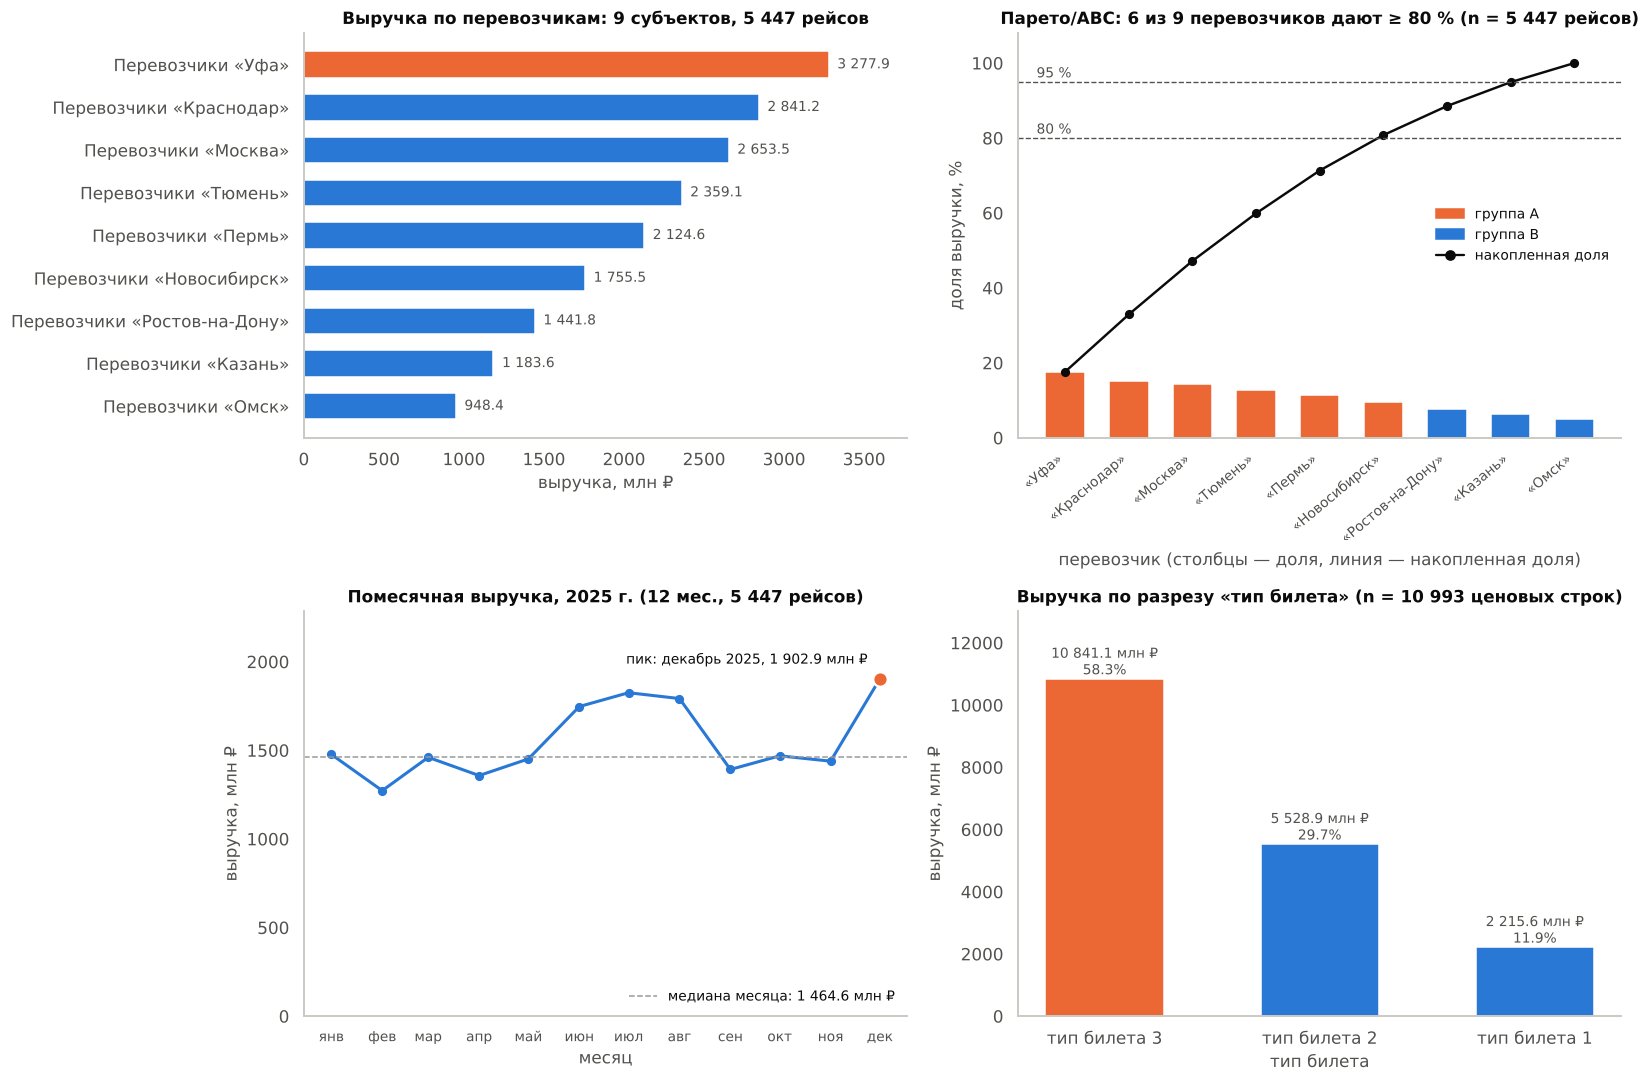

,entity_name,revenue,доля,накопленная доля,группа ABC
0,Перевозчики «Уфа»,"3,277,856,179.97",0.18,0.18,A
1,Перевозчики «Краснодар»,"2,841,215,827.81",0.15,0.33,A
2,Перевозчики «Москва»,"2,653,536,616.30",0.14,0.47,A
3,Перевозчики «Тюмень»,"2,359,117,987.30",0.13,0.60,A
4,Перевозчики «Пермь»,"2,124,578,494.70",0.11,0.71,A
5,Перевозчики «Новосибирск»,"1,755,507,015.42",0.09,0.81,A
6,Перевозчики «Ростов-на-Дону»,"1,441,817,750.58",0.08,0.89,B
7,Перевозчики «Казань»,"1,183,555,852.99",0.06,0.95,B
8,Перевозчики «Омск»,"948,391,443.66",0.05,1.00,B


,месяц,рейсов,"выручка, ₽"
0,2025-01,469,"1,476,992,403.46"
1,2025-02,412,"1,272,467,473.88"
2,2025-03,467,"1,460,432,592.87"
3,2025-04,443,"1,357,592,530.88"
4,2025-05,494,"1,451,556,412.09"
5,2025-06,438,"1,746,969,723.32"
6,2025-07,460,"1,824,974,989.40"
7,2025-08,454,"1,792,022,237.16"
8,2025-09,436,"1,392,000,298.51"
9,2025-10,454,"1,468,853,747.19"


,price_class,revenue,доля
0,тип билета 3,"10,841,081,967.90",0.58
1,тип билета 2,"5,528,867,326.52",0.30
2,тип билета 1,"2,215,627,874.32",0.12


Витрина сохранена: pw2_work/mart_events_enriched.csv (5 447 строк), pw2_work/mart_revenue_by_entity.csv и таблица mart_revenue_by_entity в SQLite

=================== ВЫВОДЫ ДЛЯ ЛПР · вариант 11 · Общественный транспорт ===================
Данные: 5 447 рейсов, 10 993 строк тарифов, 9 перевозчиков; в карантине 194 строк.
Итоговая выручка (корректная методика): 18 585 577 169 ₽.

НАБЛЮДЕНИЯ
1. Концентрация. Лидер — Перевозчики «Уфа»: 17.6% выручки; три крупнейших перевозчика
   дают 47.2%. Группа A — 6 из 9 перевозчиков (порог 80 %), группа B — 3.
2. Сезонность. Пик — декабрь 2025 (1 902.9 млн ₽),
   это в 1.30 раза выше медианного месяца; максимум к минимуму — в 1.50 раза.
   Три пиковых месяца: декабрь (1 902.9 млн ₽), июль (1 825.0 млн ₽), август (1 792.0 млн ₽).
3. Типы билетов. Наибольший вклад даёт «тип билета 3» — 58.3% выручки;
   наименьший — «тип билета 1» (11.9%).
4. Качество данных. Наивный JOIN завышает выручку в 2.03 раза (лишних 19 075 167 810 ₽);
   отчёт по такому запро

In [7]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 6.1
# Постройте четыре графика:
#   1) выручка по субъектам с выделением лидера;
#   2) диаграмма Парето с накопленной долей и группами ABC (порог 80 % и 95 %);
#   3) помесячная динамика выручки с отметкой пика и медианы;
#   4) структура выручки по разрезу цен (CFG["cls"]).
# Требования: заголовок с объёмом выборки, подписи осей с единицами, единая палитра,
# один акцентный цвет на выделяемый объект.
# палитра: один акцент (оранжевый), основной цвет (синий), нейтральный серый
ACCENT, BASE, GREY, INK, INK2 = "#eb6834", "#2a78d6", "#9a9a95", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.edgecolor": "#c9c8c2", "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "text.color": INK, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.grid": False})
def ru(x, d=1):
    return f"{x:,.{d}f}".replace(",", " ")

RU_M = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
RU_M_FULL = ["январь", "февраль", "март", "апрель", "май", "июнь", "июль", "август", "сентябрь",
             "октябрь", "ноябрь", "декабрь"]

total_revenue = float(revenue_sql["revenue"].sum())
n_ev, n_pr = len(consolidated), len(prices_valid)

# ---------------------------- срезы
by_entity = revenue_sql.sort_values("revenue", ascending=False).reset_index(drop=True)
pareto = by_entity.copy()
pareto["доля"] = pareto["revenue"] / total_revenue
pareto["накопленная доля"] = pareto["доля"].cumsum()
# группа A — субъекты, чья накопленная доля до них < 80 % (включая пересекающего порог), B — до 95 %
prev = pareto["накопленная доля"] - pareto["доля"]
pareto["группа ABC"] = np.where(prev < 0.80, "A", np.where(prev < 0.95, "B", "C"))

monthly = (consolidated.assign(month=consolidated["event_date"].dt.to_period("M").dt.to_timestamp())
           .groupby("month", as_index=False)
           .agg(revenue=("event_revenue", "sum"), events=("event_id", "count")))

# разрез по типу билета: выручку события делим поровну между его ценовыми строками —
# иначе тот же fan-out завысит сумму. Сумма по классам обязана равняться итогу.
by_class = (prices_valid.merge(events_valid[["event_id", "volume_units"]], on="event_id")
            .assign(n_rows=lambda d: d.groupby("event_id")["price_id"].transform("count"))
            .assign(revenue=lambda d: d["volume_units"] * d["unit_price"] / d["n_rows"])
            .groupby("price_class", as_index=False)["revenue"].sum()
            .sort_values("revenue", ascending=False).reset_index(drop=True))
by_class["доля"] = by_class["revenue"] / total_revenue

gaps = pd.DataFrame({
    "разрез": ["по субъектам (SQL)", "по субъектам (pandas)", f"по месяцам", f"по разрезу «{CFG['cls']}»"],
    "сумма выручки, ₽": [by_entity["revenue"].sum(), revenue_pd["revenue"].sum(),
                          monthly["revenue"].sum(), by_class["revenue"].sum()]})
gaps["отклонение от итога, ₽"] = (gaps["сумма выручки, ₽"] - total_revenue).abs()
display(gaps)
slice_gap = float(gaps["отклонение от итога, ₽"].max())
print(f"Контроль сходимости: максимальное отклонение среза от итога {slice_gap:.4f} ₽ "
      f"(допустимо только округление в SQL).")

# ---------------------------- графики
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1) выручка по субъектам, лидер выделен
ax = axes[0, 0]
top = by_entity.sort_values("revenue")
ax.barh(top["entity_name"], top["revenue"] / 1e6, height=0.62,
        color=[ACCENT if i == len(top) - 1 else BASE for i in range(len(top))])
for y, v in enumerate(top["revenue"] / 1e6):
    ax.text(v, y, f"  {ru(v)}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, top["revenue"].max() / 1e6 * 1.15)
ax.set_title(f"Выручка по перевозчикам: {len(top)} субъектов, {nf(n_ev)} рейсов")
ax.set_xlabel("выручка, млн ₽")

# 2) Парето и ABC: столбцы и накопленная доля — в одних единицах (%), одна ось
ax = axes[0, 1]
x = np.arange(len(pareto))
cmap = {"A": ACCENT, "B": BASE, "C": GREY}
ax.bar(x, pareto["доля"] * 100, width=0.62, color=[cmap[g] for g in pareto["группа ABC"]])
ax.plot(x, pareto["накопленная доля"] * 100, color=INK, marker="o", ms=5, lw=1.6)
for lvl in (80, 95):
    ax.axhline(lvl, color=INK2, ls="--", lw=0.9)
    ax.text(-0.45, lvl + 1.2, f"{lvl} %", ha="left", fontsize=9, color=INK2)
ax.set_xticks(x, pareto["entity_name"].str.replace("Перевозчики ", "", regex=False),
              rotation=40, ha="right", fontsize=9)
ax.set_ylim(0, 108)
ax.set_ylabel("доля выручки, %")
n_a = int((pareto["группа ABC"] == "A").sum()); n_b = int((pareto["группа ABC"] == "B").sum())
ax.set_title(f"Парето/ABC: {n_a} из {len(pareto)} перевозчиков дают ≥ 80 % (n = {nf(n_ev)} рейсов)")
ax.set_xlabel("перевозчик (столбцы — доля, линия — накопленная доля)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=cmap[g], label=f"группа {g}") for g in "ABC" if g in set(pareto["группа ABC"])] +
          [plt.Line2D([], [], color=INK, marker="o", label="накопленная доля")],
          loc="center right", fontsize=9, frameon=False)

# 3) сезонность: пик и медиана
ax = axes[1, 0]
ax.plot(monthly["month"], monthly["revenue"] / 1e6, color=BASE, lw=2, marker="o", ms=5)
peak = monthly.loc[monthly["revenue"].idxmax()]
med = monthly["revenue"].median() / 1e6
ax.scatter([peak["month"]], [peak["revenue"] / 1e6], color=ACCENT, s=90, zorder=3,
           edgecolor="white", linewidth=1.5)
ax.annotate(f"пик: {RU_M_FULL[peak['month'].month - 1]} {peak['month'].year}, {ru(peak['revenue'] / 1e6)} млн ₽",
            (peak["month"], peak["revenue"] / 1e6), textcoords="offset points", xytext=(-8, 10),
            ha="right", fontsize=9, color=INK)
ax.axhline(med, color=GREY, ls="--", lw=1, label=f"медиана месяца: {ru(med)} млн ₽")
ax.legend(loc="lower right", fontsize=9, frameon=False)
ax.set_xticks(monthly["month"], [RU_M[m.month - 1] for m in monthly["month"]], fontsize=9)
ax.set_ylim(0, monthly["revenue"].max() / 1e6 * 1.2)
ax.set_title(f"Помесячная выручка, 2025 г. ({len(monthly)} мес., {nf(n_ev)} рейсов)")
ax.set_xlabel("месяц"); ax.set_ylabel("выручка, млн ₽")

# 4) структура по типам билета
ax = axes[1, 1]
ax.bar(by_class["price_class"], by_class["revenue"] / 1e6, width=0.55,
       color=[ACCENT if i == 0 else BASE for i in range(len(by_class))])
for i, (v, s) in enumerate(zip(by_class["revenue"] / 1e6, by_class["доля"])):
    ax.text(i, v, f"{ru(v)} млн ₽\n{s:.1%}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_ylim(0, by_class["revenue"].max() / 1e6 * 1.2)
ax.set_title(f"Выручка по разрезу «{CFG['cls']}» (n = {nf(n_pr)} ценовых строк)")
ax.set_xlabel(CFG["cls"]); ax.set_ylabel("выручка, млн ₽")

for a in axes.flat:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(WORK / "fig_analytics.png", dpi=130, bbox_inches="tight")
plt.show()
PLOTS_DONE = True

display(pareto[["entity_name", "revenue", "доля", "накопленная доля", "группа ABC"]])
display(monthly.assign(месяц=monthly["month"].dt.strftime("%Y-%m"))[["месяц", "events", "revenue"]]
        .rename(columns={"events": "рейсов", "revenue": "выручка, ₽"}))
display(by_class)

# ---------------------------- витрина (сохраняется рядом с базой)
mart = consolidated[["event_id", "entity_id", "entity_name", "region", "event_date", "route",
                     "asset_type", "volume_units", "unit_price", "event_revenue"]].rename(
    columns={"unit_price": "avg_unit_price"})
mart.to_csv(WORK / "mart_events_enriched.csv", index=False, encoding="utf-8-sig")
revenue_sql.to_csv(WORK / "mart_revenue_by_entity.csv", index=False, encoding="utf-8-sig")
revenue_sql.to_sql("mart_revenue_by_entity", conn, if_exists="replace", index=False)
conn.commit()
print(f"Витрина сохранена: {WORK / 'mart_events_enriched.csv'} ({nf(len(mart))} строк), "
      f"{WORK / 'mart_revenue_by_entity.csv'} и таблица mart_revenue_by_entity в SQLite")

# ------------------------------------------------------------------ TODO 6.2
# Сформируйте выводы для ЛПР: концентрация выручки, сезонность, влияние качества данных
# (коэффициент завышения из шага 5) и три рекомендации с ожидаемым эффектом.
leader = pareto.iloc[0]
share_top3 = float(pareto["доля"].head(3).sum())
peak_rev, med_rev = float(peak["revenue"]), float(monthly["revenue"].median())
top_months = monthly.nlargest(3, "revenue")
top_months_txt = ", ".join(f"{RU_M_FULL[m.month - 1]} ({ru(r / 1e6)} млн ₽)"
                           for m, r in zip(top_months["month"], top_months["revenue"]))
season_gap = float(monthly["revenue"].max() / monthly["revenue"].min())
top_cls, top_cls_share = by_class.iloc[0]["price_class"], float(by_class.iloc[0]["доля"])
low_cls = by_class.iloc[-1]
phantom = float(compare["revenue_naive"].sum() - compare["revenue"].sum())
q_total = len(quarantine_fk) + len(quarantine_event) + len(quarantine_price)
peak_months_rev = float(top_months["revenue"].sum())
n_noprice = len(events_valid) - len(consolidated)       # события без единой пригодной цены

print(f"""
=================== ВЫВОДЫ ДЛЯ ЛПР · вариант {VARIANT} · {CFG['domain']} ===================
Данные: {nf(n_ev)} рейсов, {nf(n_pr)} строк тарифов, {len(entities)} перевозчиков; в карантине {q_total} строк.
Итоговая выручка (корректная методика): {nf(total_revenue)} ₽.

НАБЛЮДЕНИЯ
1. Концентрация. Лидер — {leader['entity_name']}: {leader['доля']:.1%} выручки; три крупнейших перевозчика
   дают {share_top3:.1%}. Группа A — {n_a} из {len(pareto)} перевозчиков (порог 80 %), группа B — {n_b}.
2. Сезонность. Пик — {RU_M_FULL[peak['month'].month - 1]} {peak['month'].year} ({ru(peak_rev / 1e6)} млн ₽),
   это в {peak_rev / med_rev:.2f} раза выше медианного месяца; максимум к минимуму — в {season_gap:.2f} раза.
   Три пиковых месяца: {top_months_txt}.
3. Типы билетов. Наибольший вклад даёт «{top_cls}» — {top_cls_share:.1%} выручки;
   наименьший — «{low_cls['price_class']}» ({low_cls['доля']:.1%}).
4. Качество данных. Наивный JOIN завышает выручку в {overstate:.2f} раза (лишних {nf(phantom)} ₽);
   отчёт по такому запросу привёл бы к решениям на «фантомной» выручке.

РЕКОМЕНДАЦИИ (эффекты — сценарные оценки на этих данных, не прогноз)
1. Сосредоточить управленческое внимание на группе A ({n_a} перевозчиков, {pareto[pareto['группа ABC'] == 'A']['доля'].sum():.0%} выручки):
   еженедельный контроль выручки и регулярности рейсов; для группы B ({n_b} перевозчика) — отдельный план роста.
   Ожидаемый эффект: рост выручки группы A всего на 3 % даёт ≈ {ru(0.03 * pareto[pareto['группа ABC'] == 'A']['revenue'].sum() / 1e6)} млн ₽ в год.
   Проверка: сравнить динамику группы A с контрольной группой B за 2–3 месяца.
2. Подстроить мощность и тарифы под сезон: на три пиковых месяца приходится {peak_months_rev / total_revenue:.0%} выручки.
   Ожидаемый эффект: +5 % к выручке пиковых месяцев (дополнительные рейсы или пиковый тариф) ≈ {ru(0.05 * peak_months_rev / 1e6)} млн ₽.
   Проверка: пилот на 2–3 маршрутах в ближайший пик, сравнение с аналогичными маршрутами без изменений.
3. Закрепить методику отчётности: свёртка цен до уровня рейса, ссылочная целостность и карантин на входе.
   Ожидаемый эффект: исключается завышение в {overstate:.2f} раза ({nf(phantom)} ₽ «лишней» выручки);
   {q_total} проблемных строк разбираются с владельцем данных, а не теряются.
   Проверка: автотест сверки SQL и pandas на каждой загрузке (расхождение < 1 ₽) и доля карантина < 1 %.

ОГРАНИЧЕНИЯ ДАННЫХ
• Цена рейса — простое среднее по его тарифным строкам (допущение учебной модели): без числа проданных
  билетов по типам реальная выручка может быть выше или ниже; взвешенная цена даст другой итог.
• В выручку не вошли рейсы без пригодного объёма ({len(quarantine_event)}), с неизвестным перевозчиком ({len(quarantine_fk)})
  и без единой валидной цены ({n_noprice}); поэтому итог — нижняя оценка по пригодным данным.
• Один год наблюдений (2025): сезонность подтверждена одним циклом, а не повторяется на нескольких годах.
• Данные синтетические; выбросы по 3×IQR помечены флагом, а не удалены.
==================================================================================
""")

**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [8]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "my-gcp-project"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: основная часть работы выполняется на SQLite.


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [9]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [10]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.